# Car Racing Agent: comparing A* heuristics (Deliverable 2)

**CSE518 Artificial Intelligence, Project Part 1 · Car Racing Agent**

The deliberative layer of the racing car plans its lap with **A\*** on an occupancy grid of the track:
8 px cells, 8-connected, with cells too close to a wall removed. The cost of a move is its length times a
wall-proximity penalty (≥ 1), so the planner prefers the middle of the road. Start and goal are both on the
start/finish line. A barrier across the line forces A\* to plan the **whole lap**.

| id | heuristic | admissible? | idea |
|----|-----------|-------------|------|
| h0 | Dijkstra (h = 0) | yes | baseline |
| **h1** | Euclidean | yes | straight-line distance |
| **h2** | Manhattan | **no** (8-connected grid) | \|dx\|+\|dy\| over-estimates diagonal moves |
| **h3** | Octile | yes | exact distance on an empty 8-connected grid |
| **h4** | ALT landmarks | yes | triangle inequality with exact distances from 8 landmarks spread around the track |

h1–h4 are the four heuristics we compare. After the search comparison, the notebook also compares the
**driving agents** (A\* path follower vs utility agent vs reflex agent vs learned agent) on lap time.

**Contents:** 1 tracks · 2 full-lap search · 3 random queries · 4 where A\* searches · 5 admissibility & informedness ·
6 ALT landmark count · 7 driving: time trials, race, learning curve · 8 conclusions

In [1]:
import sys, time, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from racing.track import load_track
from racing.planner import Grid, astar, HEURISTICS, plan_lap
from racing import experiments as X
from racing.learning import load_model

FIG = ROOT / "report" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#b5b3ad",
    "axes.grid": True, "grid.color": "#e6e4de", "grid.linewidth": 0.7, "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlesize": 11, "legend.frameon": False})
pd.set_option("display.width", 170, "display.max_columns", 30)
HC = X.H_COLORS; HS = X.HS
tracks = {n: load_track(ROOT / f"tracks/{n}.track") for n in ["serpentine", "technical", "oval"]}
model = ROOT / "models/ga_best.json"
W_GA, META = load_model(model) if model.exists() else (None, None)
for n, t in tracks.items():
    print(f"{n:11s} {t.name:30s} lap {t.length:6.0f}px  width {t.track_width:.0f}px  obstacles {len(t.obstacles)}")

serpentine  Serpentine (proposal sketch)   lap   4239px  width 80px  obstacles 2
technical   Technical Circuit              lap   3552px  width 82px  obstacles 1
oval        Oval Speedway                  lap   2349px  width 100px  obstacles 0


## 1. Tracks
The serpentine track reproduces the hand-drawn track from the project proposal. Brown dots are rocks on the road.

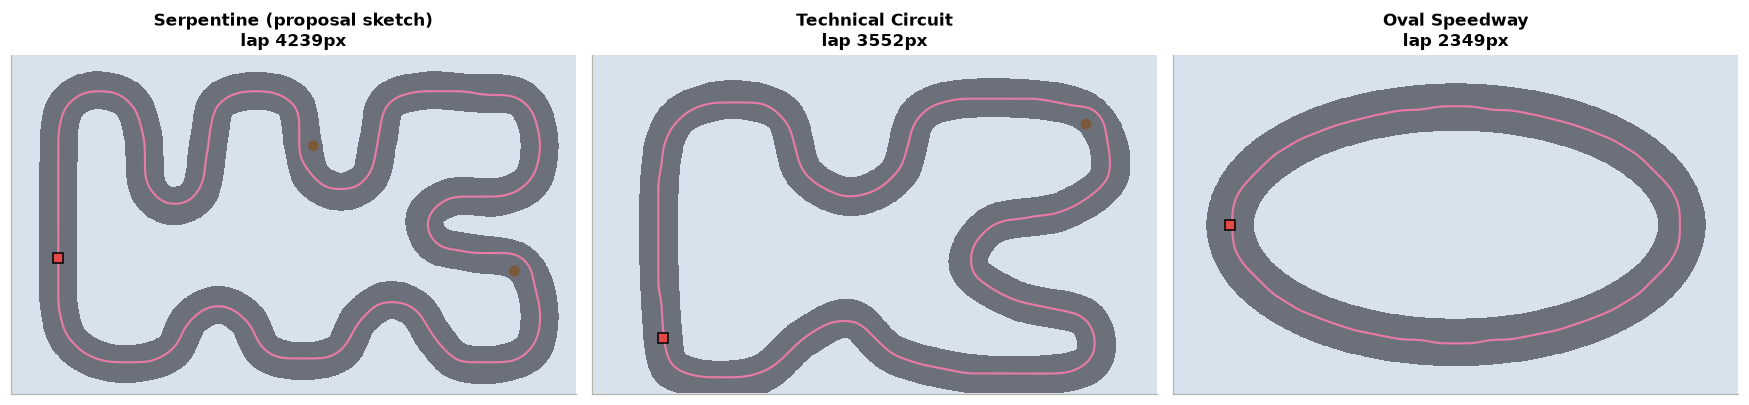

In [2]:
def show_track(t, ax, title=None, overlay=None, lines=()):
    img = np.where(t.mask[..., None], np.array([0.42, 0.44, 0.48]), np.array([0.85, 0.89, 0.93]))
    ax.imshow(img, interpolation="nearest")
    if overlay is not None:
        ax.imshow(overlay, cmap=ListedColormap(["#3987e5"]), alpha=0.85, interpolation="nearest",
                  extent=(0, t.width_px, t.height_px, 0))
    for (pts, col, lw) in lines:
        ax.plot(pts[:, 0], pts[:, 1], color=col, lw=lw)
    for (x, y, r) in t.obstacles:
        ax.add_patch(plt.Circle((x, y), r, color="#7a5a3a"))
    sx, sy = t.start_pos; ax.plot(sx, sy, marker="s", ms=7, color="#e34948", mec="k")
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    if title: ax.set_title(title)

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, (n, t) in zip(axes, tracks.items()):
    _, res, line = plan_lap(t, "h4")
    show_track(t, ax, f"{t.name}\nlap {t.length:.0f}px", lines=[(line.pts, "#e87ba4", 1.4)])
plt.tight_layout(); plt.savefig(FIG / "tracks.png", bbox_inches="tight"); plt.show()

## 2. Full-lap planning (the query the car actually makes)
The goal lies right behind the start line, so the **straight-line distance to the goal is tiny while the real
cost is a whole lap**. This is the worst case for purely geometric heuristics.

In [3]:
lap = X.lap_search_table(tracks)
lap[["track","heuristic","description","cost","gap_pct","expanded","expanded_vs_dijkstra","generated","ms","free_cells","alt_precompute_ms"]]

,track,heuristic,description,cost,gap_pct,expanded,expanded_vs_dijkstra,generated,ms,free_cells,alt_precompute_ms
0,serpentine,h0,"Dijkstra (h = 0, baseline)",4638.0,0.00,3215,1.000,4086,32.54,3235,0.0
1,serpentine,h1,Euclidean distance,4638.0,0.00,3124,0.972,4506,32.14,3235,0.0
2,serpentine,h2,Manhattan distance,4659.4,0.46,9919,3.085,13850,117.19,3235,0.0
3,serpentine,h3,Octile distance,4638.0,0.00,3094,0.962,4532,38.83,3235,0.0
4,serpentine,h4,ALT landmarks,4638.0,0.00,811,0.252,2587,15.88,3235,6.9
5,technical,h0,"Dijkstra (h = 0, baseline)",3916.0,0.00,2785,1.000,3496,37.34,2800,0.0
6,technical,h1,Euclidean distance,3916.0,0.00,2745,0.986,3814,30.95,2800,0.0
7,technical,h2,Manhattan distance,3923.0,0.18,16004,5.746,20992,188.15,2800,0.0
8,technical,h3,Octile distance,3916.0,0.00,2743,0.985,3861,40.07,2800,0.0
9,technical,h4,ALT landmarks,3916.0,0.00,804,0.289,2426,12.69,2800,4.6


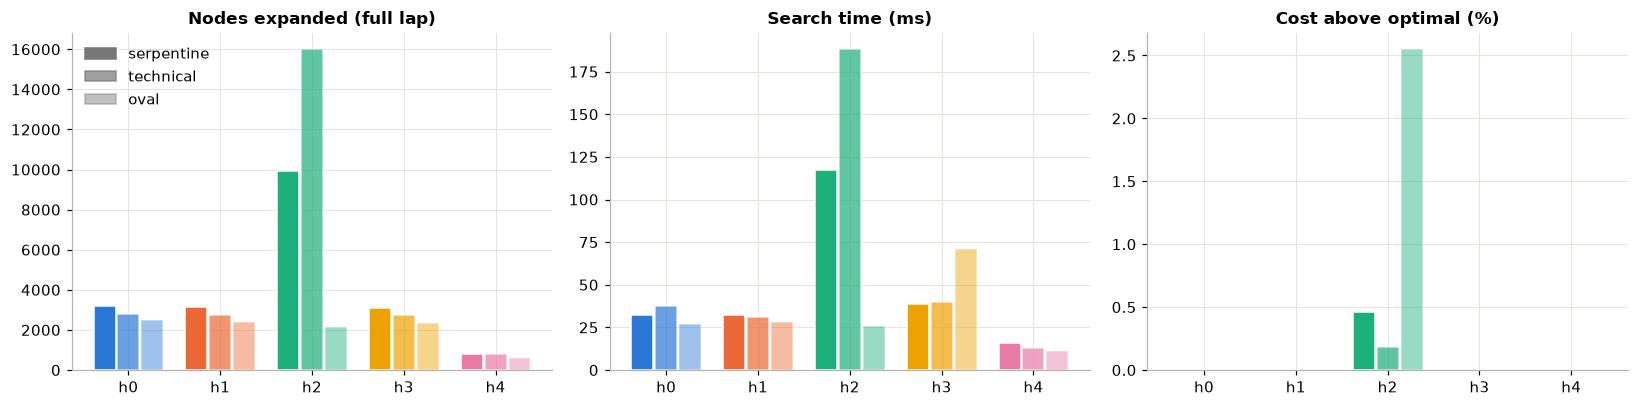

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
names = list(tracks)
x = np.arange(len(HS)); w = 0.26
for ax, (metric, title) in zip(axes, [("expanded", "Nodes expanded (full lap)"), ("ms", "Search time (ms)"),
                                       ("gap_pct", "Cost above optimal (%)")]):
    for j, n in enumerate(names):
        v = lap[lap.track == n].set_index("heuristic").loc[HS, metric].values
        ax.bar(x + (j - 1) * w, v, w * 0.92, color=[HC[h] for h in HS], alpha=[1, 0.7, 0.45][j], edgecolor="white")
    ax.set_xticks(x, HS); ax.set_title(title)
axes[0].legend(handles=[Patch(color="#777", alpha=a, label=n) for n, a in zip(names, [1, .7, .45])], loc="upper left")
plt.tight_layout(); plt.savefig(FIG / "lap_bars.png", bbox_inches="tight"); plt.show()

**Observations.** Euclidean and Octile hardly beat Dijkstra on a full lap: from most cells they "think" the goal
is only a few cells away. Manhattan is inadmissible. It finds a slightly more expensive lap, and because it is
inconsistent it **re-opens** nodes, so it can expand *more* nodes than there are free cells. ALT is the only
heuristic that knows the track goes around, and it cuts the work by roughly 3–4×.

## 3. Random start/goal queries
120 random pairs of free cells per track (no barrier). This is closer to the usual A\* setting.

In [5]:
rp = X.random_pairs_table(tracks, n=120)
summ = rp.groupby("heuristic").agg(mean_expanded=("expanded","mean"), median_expanded=("expanded","median"),
        mean_ms=("ms","mean"), optimal_pct=("gap_pct", lambda g: 100*(g.abs()<1e-6).mean()),
        max_gap_pct=("gap_pct","max")).round(2)
summ["vs_dijkstra"] = (summ.mean_expanded / summ.loc["h0","mean_expanded"]).round(3)
summ.insert(0, "description", [HEURISTICS[h] for h in summ.index]); summ

,description,mean_expanded,median_expanded,mean_ms,optimal_pct,max_gap_pct,vs_dijkstra
heuristic,,,,,,,
h0,"Dijkstra (h = 0, baseline)",1390.39,1313.0,20.18,100.00,0.00,1.000
h1,Euclidean distance,952.62,770.0,14.39,100.00,0.00,0.685
h2,Manhattan distance,3208.52,940.5,50.49,15.28,16.15,2.308
h3,Octile distance,906.69,722.5,13.67,100.00,0.00,0.652
h4,ALT landmarks,306.96,198.5,5.61,100.00,0.00,0.221


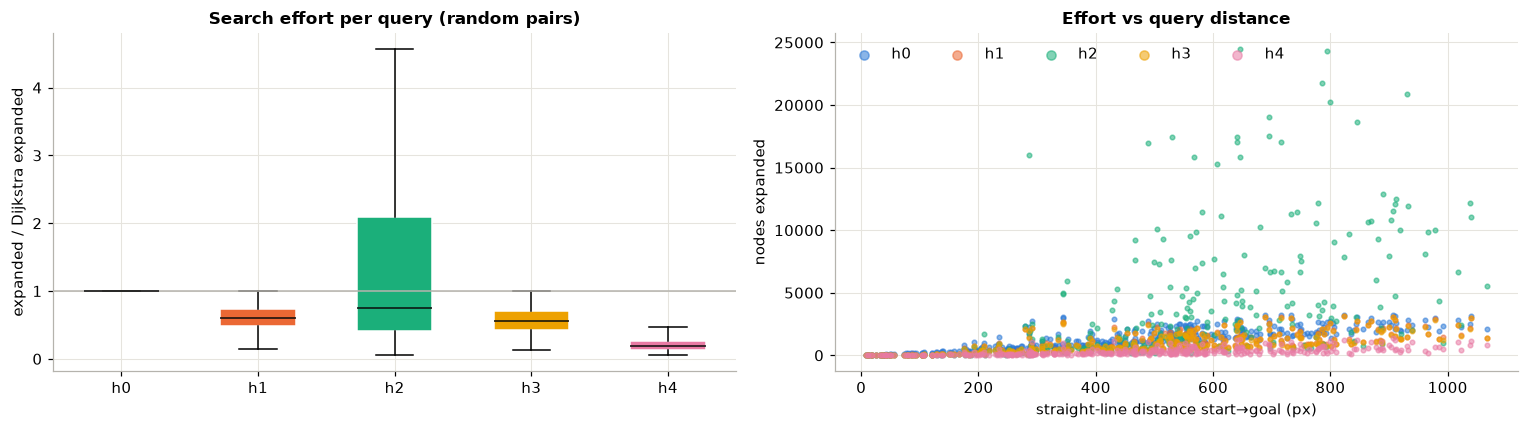

In [6]:
rel = rp.pivot_table(index=["track","query"], columns="heuristic", values="expanded")
rel = rel.div(rel["h0"], axis=0)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
bp = axes[0].boxplot([rel[h].values for h in HS], tick_labels=HS, patch_artist=True, showfliers=False,
                     widths=0.55, medianprops=dict(color="#0b0b0b"))
for p, h in zip(bp["boxes"], HS): p.set_facecolor(HC[h]); p.set_edgecolor("white")
axes[0].axhline(1, color="#b5b3ad", lw=1); axes[0].set_ylabel("expanded / Dijkstra expanded")
axes[0].set_title("Search effort per query (random pairs)")
for h in HS:
    d = rp[rp.heuristic == h]
    axes[1].scatter(d.straight_px, d.expanded, s=9, color=HC[h], alpha=0.55, label=h)
axes[1].set_xlabel("straight-line distance start→goal (px)"); axes[1].set_ylabel("nodes expanded")
axes[1].set_title("Effort vs query distance"); axes[1].legend(ncol=5, loc="upper left", markerscale=2)
plt.tight_layout(); plt.savefig(FIG / "random_pairs.png", bbox_inches="tight"); plt.show()

## 4. Where does A\* search? (closed set of the full-lap query on the serpentine track)

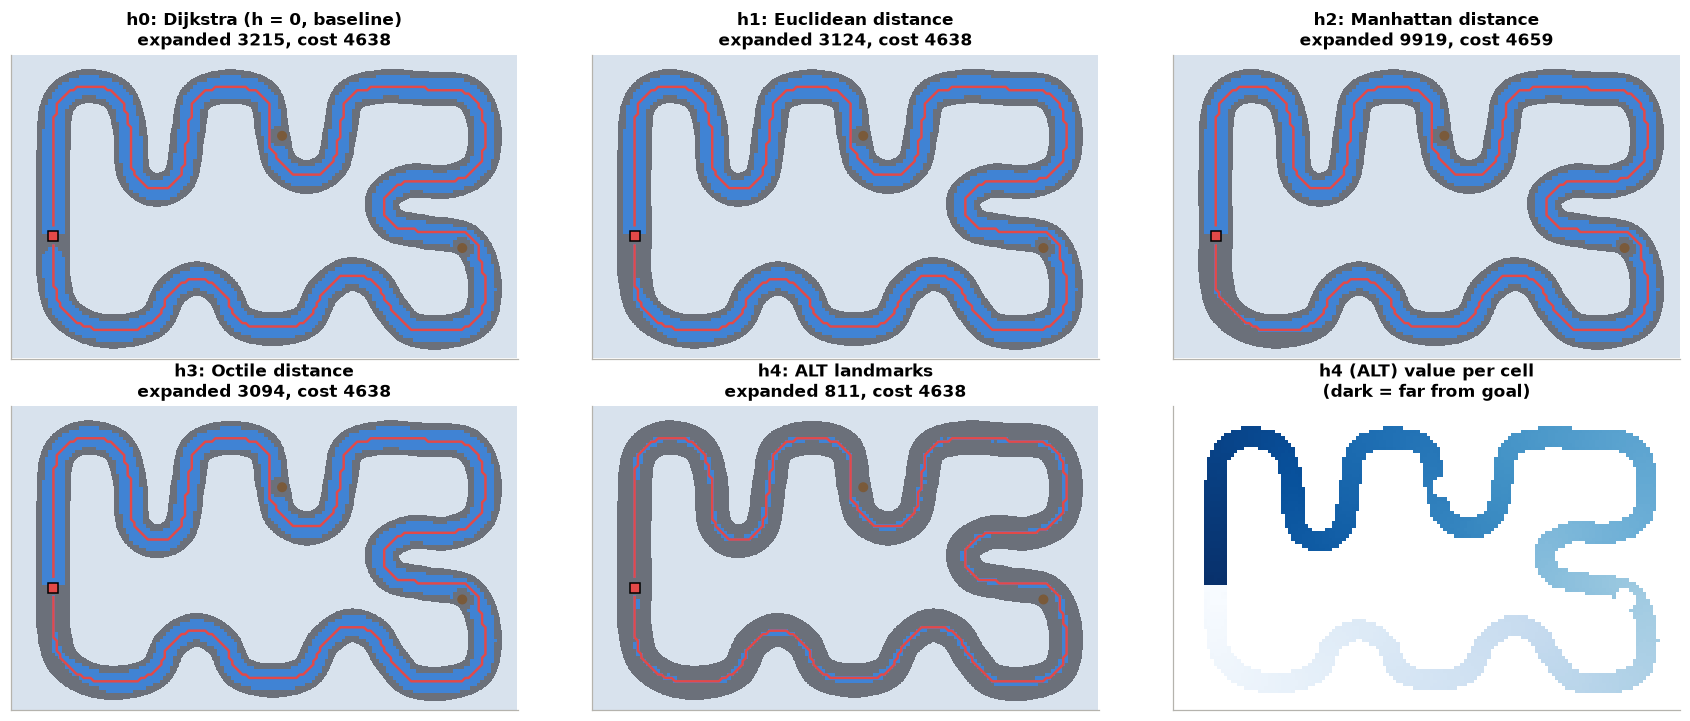

In [7]:
t = tracks["serpentine"]; g = Grid(t); s, goal = g.lap_endpoints()
fig, axes = plt.subplots(2, 3, figsize=(16, 6.6))
for ax, h in zip(axes.ravel(), HS):
    r = astar(g, s, goal, h, keep_closed=True)
    ov = np.ma.masked_where(~r.closed, r.closed.astype(float))
    pts = np.array([g.to_xy(c) for c in r.cells])
    show_track(t, ax, f"{h}: {HEURISTICS[h]}\nexpanded {r.expanded}, cost {r.cost:.0f}", overlay=ov,
               lines=[(pts, "#e34948", 1.6)])
ax = axes.ravel()[-1]
from racing.planner import heuristic_table
H = np.ma.masked_where(~g.free, heuristic_table(g, "h4", goal))
ax.imshow(H, cmap="Blues", extent=(0, t.width_px, t.height_px, 0)); ax.set_title("h4 (ALT) value per cell\n(dark = far from goal)")
ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
plt.tight_layout(); plt.savefig(FIG / "closed_sets.png", bbox_inches="tight"); plt.show()

## 5. Admissibility, consistency and informedness
For every free cell *n* we compute the exact cost-to-goal *h\*(n)* with Dijkstra. We then report the mean
ratio h/h\* (1 = perfect), the number of over-estimates, and the number of edges where h(n) > c(n,n') + h(n').

In [8]:
inf = X.informedness(tracks); inf

,track,heuristic,mean_h_over_hstar,max_h_over_hstar,overestimates,admissible,consistency_violations
0,serpentine,h1,0.398,1.000,0,True,0
1,serpentine,h2,0.485,1.250,234,False,1502
2,serpentine,h3,0.421,1.000,0,True,0
3,serpentine,h4,0.993,1.000,0,True,0
4,technical,h1,0.434,0.958,0,True,0
5,technical,h2,0.517,1.274,74,False,1231
6,technical,h3,0.453,0.967,0,True,0
7,technical,h4,0.992,1.000,0,True,0
8,oval,h1,0.572,0.982,0,True,0
9,oval,h2,0.723,1.297,842,False,1029


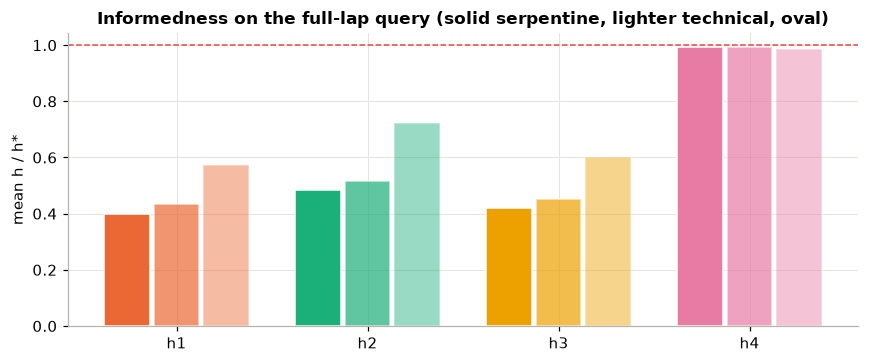

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.4))
hh = HS[1:]; x = np.arange(len(hh)); w = 0.26
for j, n in enumerate(names):
    v = inf[inf.track == n].set_index("heuristic").loc[hh, "mean_h_over_hstar"]
    ax.bar(x + (j-1)*w, v, w*0.92, color=[HC[h] for h in hh], alpha=[1, .7, .45][j], edgecolor="white")
ax.axhline(1, color="#e34948", ls="--", lw=1); ax.set_xticks(x, hh); ax.set_ylabel("mean h / h*")
ax.set_title("Informedness on the full-lap query (solid serpentine, lighter technical, oval)")
plt.tight_layout(); plt.savefig(FIG / "informedness.png", bbox_inches="tight"); plt.show()

## 6. How many landmarks does ALT need? (serpentine, full lap)

,landmarks,expanded,search_ms,precompute_ms
0,1,898,11.84,2.1
1,2,870,11.34,2.1
2,3,850,10.90,2.4
3,4,818,10.68,2.9
4,6,814,10.60,3.7
5,8,811,10.91,5.0
6,12,821,11.56,7.6
7,16,784,11.56,11.3


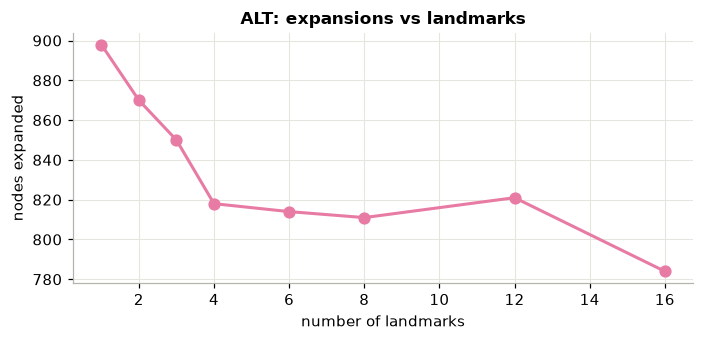

In [10]:
sw = X.landmark_sweep(tracks["serpentine"], ks=(1, 2, 3, 4, 6, 8, 12, 16)); display(sw)
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(sw.landmarks, sw.expanded, marker="o", ms=7, lw=2, color=HC["h4"])
ax.set_xlabel("number of landmarks"); ax.set_ylabel("nodes expanded"); ax.set_title("ALT: expansions vs landmarks")
plt.tight_layout(); plt.savefig(FIG / "alt_sweep.png", bbox_inches="tight"); plt.show()

## 7. Driving: does the heuristic matter on the road, and who is the better AI?
**Time trials:** each agent drives one lap alone from the start line. The A\* cars differ only in the
heuristic used to plan.

In [11]:
tt = X.time_trials(tracks, W_GA)
pivot = tt.pivot_table(index="agent", columns="track", values="lap_time")
status = tt.pivot_table(index="agent", columns="track", values="status", aggfunc="first")
display(pivot.round(2)); display(status)
tt

track,oval,serpentine,technical
agent,,,
A* (h1),11.83,24.20,18.33
A* (h2),11.87,24.20,18.30
A* (h3),11.83,24.20,18.33
A* (h4),11.83,24.20,18.33
Learned (GA),10.17,23.13,17.70
Reflex,10.27,26.67,19.30
Utility,9.73,21.43,15.87


track,oval,serpentine,technical
agent,,,
A* (h1),FINISHED,FINISHED,FINISHED
A* (h2),FINISHED,FINISHED,FINISHED
A* (h3),FINISHED,FINISHED,FINISHED
A* (h4),FINISHED,FINISHED,FINISHED
Learned (GA),FINISHED,FINISHED,FINISHED
Reflex,FINISHED,FINISHED,FINISHED
Utility,FINISHED,FINISHED,FINISHED


,track,agent,status,lap_time,avg_speed,top_speed,distance,cpu_ms_per_tick
0,serpentine,A* (h1),FINISHED,24.20,182.1,213.1,4407,0.273
1,serpentine,A* (h2),FINISHED,24.20,182.0,213.1,4405,0.357
2,serpentine,A* (h3),FINISHED,24.20,182.1,213.1,4407,0.248
3,serpentine,A* (h4),FINISHED,24.20,182.1,213.1,4407,0.234
4,serpentine,Utility,FINISHED,21.43,190.4,260.0,4081,1.382
5,serpentine,Reflex,FINISHED,26.67,154.8,238.5,4127,0.172
6,serpentine,Learned (GA),FINISHED,23.13,187.4,260.0,4334,0.195
7,technical,A* (h1),FINISHED,18.33,191.4,213.1,3509,0.268
8,technical,A* (h2),FINISHED,18.30,191.3,213.1,3500,0.531
9,technical,A* (h3),FINISHED,18.33,191.4,213.1,3509,0.258


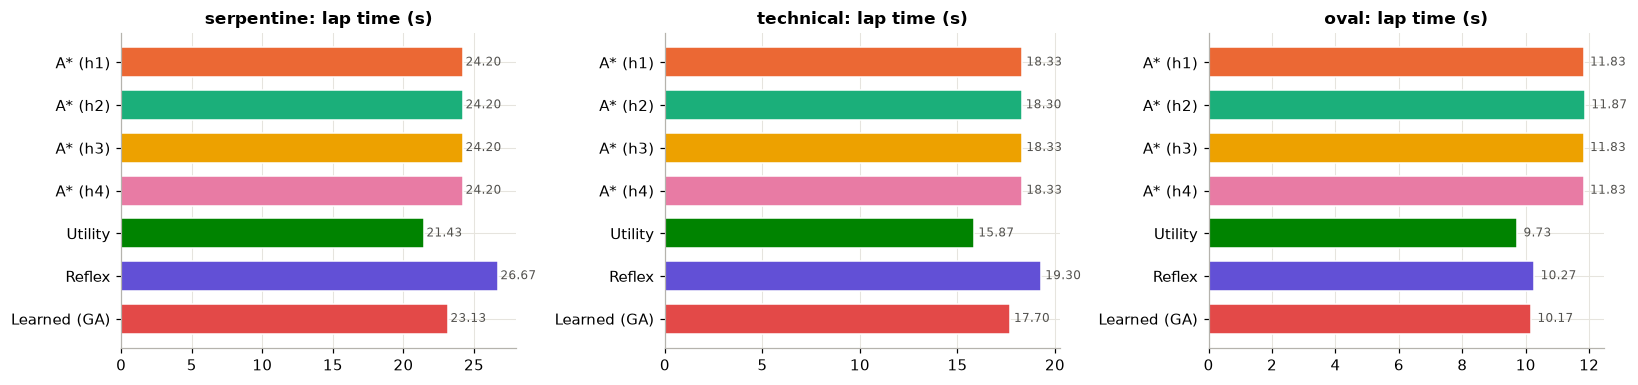

In [12]:
agents = list(pivot.index)
order = [a for a in ["A* (h1)","A* (h2)","A* (h3)","A* (h4)","Utility","Reflex","Learned (GA)"] if a in agents]
cols = {"A* (h1)": HC["h1"], "A* (h2)": HC["h2"], "A* (h3)": HC["h3"], "A* (h4)": HC["h4"],
        "Utility": "#008300", "Reflex": "#6250d6", "Learned (GA)": "#e34948"}
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), sharey=False)
for ax, n in zip(axes, names):
    v = [pivot.loc[a, n] for a in order]
    ax.barh(range(len(order)), v, color=[cols[a] for a in order], height=0.7, edgecolor="white")
    ax.set_yticks(range(len(order)), order); ax.invert_yaxis(); ax.set_title(f"{n}: lap time (s)")
    for i, val in enumerate(v):
        ax.text((val if np.isfinite(val) else 0) + 0.2, i, f"{val:.2f}" if np.isfinite(val) else "DNF", va="center", fontsize=8, color="#52514e")
plt.tight_layout(); plt.savefig(FIG / "time_trials.png", bbox_inches="tight"); plt.show()

**The race:** all cars start together from a staggered grid behind the line (ghost cars, so there is no contact).

In [13]:
from racing.agents import default_lineup
for n, t in tracks.items():
    print(n); display(X.race_table(t, default_lineup(W_GA))[["pos","car","kind","status","lap_time","avg_speed","top_speed"]])

serpentine


,pos,car,kind,status,lap_time,avg_speed,top_speed
0,1,Utility,utility,FINISHED,22.00,190.8,260.0
1,2,Learned (GA),neuro,FINISHED,23.57,188.1,260.0
2,3,A* h2,astar,FINISHED,24.17,181.7,213.1
3,4,A* h3,astar,FINISHED,24.17,183.3,213.1
4,5,A* h1,astar,FINISHED,24.20,182.1,213.1
5,6,A* h4,astar,FINISHED,24.30,183.0,213.1
6,7,Reflex,reflex,FINISHED,26.63,157.1,255.9


technical


,pos,car,kind,status,lap_time,avg_speed,top_speed
0,1,Utility,utility,FINISHED,15.90,216.8,260.0
1,2,Learned (GA),neuro,FINISHED,18.10,205.3,260.0
2,3,A* h1,astar,FINISHED,18.33,191.4,213.1
3,4,A* h2,astar,FINISHED,18.33,192.2,213.1
4,5,A* h3,astar,FINISHED,18.37,191.9,213.1
5,6,A* h4,astar,FINISHED,18.40,192.5,213.1
6,7,Reflex,reflex,FINISHED,19.67,181.4,260.0


oval


,pos,car,kind,status,lap_time,avg_speed,top_speed
0,1,Utility,utility,FINISHED,9.90,237.2,260.0
1,2,Learned (GA),neuro,FINISHED,10.50,238.0,260.0
2,3,Reflex,reflex,FINISHED,10.53,229.9,260.0
3,4,A* h1,astar,FINISHED,11.83,198.3,213.1
4,5,A* h2,astar,FINISHED,11.87,197.1,213.1
5,6,A* h3,astar,FINISHED,11.93,198.4,213.1
6,7,A* h4,astar,FINISHED,11.97,198.4,213.1


**Which rules fire?** Share of ticks per rule (serpentine). The A\* car mostly follows its path (P1); the safety rules S1–S3 step in only near walls.

In [14]:
ru = X.rule_usage(tracks["serpentine"]); ru

,agent,rule,ticks,share_pct
0,Reflex,R8,522,65.2
1,Reflex,R11,177,22.1
2,Reflex,R10,41,5.1
3,Reflex,R9,29,3.6
4,Reflex,R3,13,1.6
5,Reflex,R7,8,1.0
6,Reflex,R4,3,0.4
7,Reflex,R1,3,0.4
8,Reflex,R5,2,0.2
9,Reflex,R6,2,0.2


**Learning curve of the GA driver** (population 60, trained on serpentine + technical; the oval is never seen in training).

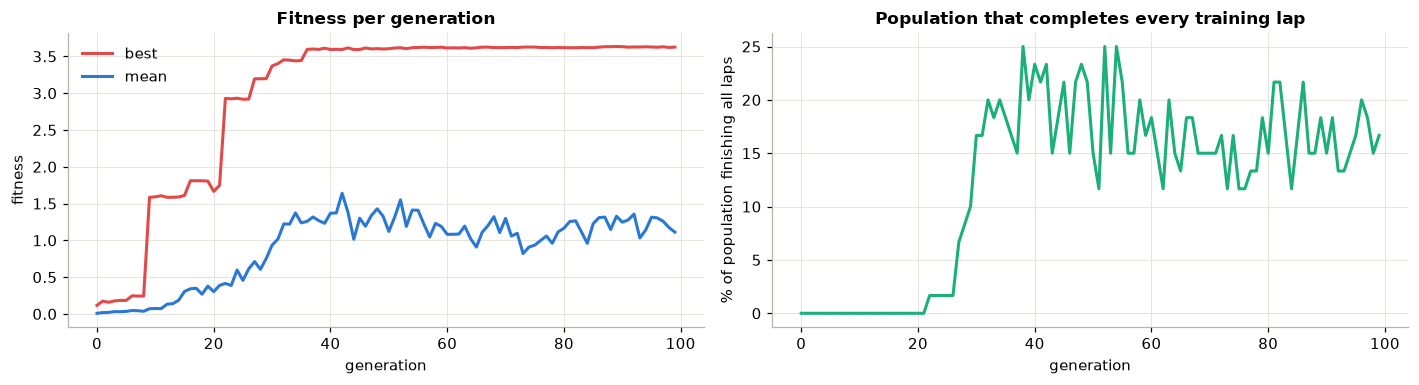

config: {'population': 60, 'generations': 100, 'elite': 6, 'tournament': 3, 'mutation_rate': 0.15, 'mutation_sigma': 0.35, 'immigrants': 4, 'init_sigma': 0.9, 'max_time': 45.0, 'seed': 7}
trained on: ['serpentine', 'technical']


In [15]:
if META:
    hst = META["history"]
    fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
    axes[0].plot(hst["best"], color="#e34948", lw=2, label="best"); axes[0].plot(hst["mean"], color="#2a78d6", lw=2, label="mean")
    axes[0].set_xlabel("generation"); axes[0].set_ylabel("fitness"); axes[0].set_title("Fitness per generation"); axes[0].legend()
    axes[1].plot(np.array(hst["finish_rate"]) * 100, color="#1baf7a", lw=2)
    axes[1].set_xlabel("generation"); axes[1].set_ylabel("% of population finishing all laps")
    axes[1].set_title("Population that completes every training lap")
    plt.tight_layout(); plt.savefig(FIG / "ga_learning.png", bbox_inches="tight"); plt.show()
    print("config:", META["config"]); print("trained on:", META["train_tracks"])

In [16]:
lap.to_csv(FIG / "lap_search.csv", index=False); summ.to_csv(FIG / "random_pairs_summary.csv")
inf.to_csv(FIG / "informedness.csv", index=False); sw.to_csv(FIG / "alt_sweep.csv", index=False)
tt.to_csv(FIG / "time_trials.csv", index=False); ru.to_csv(FIG / "rule_usage.csv", index=False)
print("saved tables to", FIG)

saved tables to D:\University\AI\project\report\figures


## 8. Conclusions
* **Admissible heuristics (h1, h3, h4) always return the optimal path.** Verified on every query. Only the
  search effort differs. **Manhattan (h2) is inadmissible** on an 8-connected grid: it returns slightly costlier
  paths, and because it is inconsistent it re-opens nodes, which can make it *slower* than Dijkstra.
* **Geometry alone is a poor guide on a race track.** Euclidean and Octile help on short random queries, but
  on the full-lap query they are almost useless, because the goal is a few cells behind the start.
* **ALT (h4) is the clear winner**: mean h/h\* close to 1. It expands about 3–4× fewer nodes than Dijkstra on a lap, and
  several times fewer on random queries. It pays a one-off pre-computation (a few Dijkstra runs, each tens of ms
  with scipy) that is reused by every later plan. Even one well-placed (farthest-point) landmark captures most of the gain on a loop track;
  more landmarks give only small extra savings for a growing pre-computation.
* **On the road, the heuristic hardly matters**: admissible heuristics give the same optimal path, so A\*
  cars with h1/h3/h4 post almost identical lap times. The heuristic is a *planning-time* choice.
* **Better AI than AI?** The model-based **utility agent** is the fastest hand-made AI. The **learned GA driver**,
  with no rules or map at all, is competitive and generalises to the unseen oval. The **reflex agent** is safe
  but slowest. The **A\*** cars are the most predictable and robust, but conservative, because the cost function
  keeps them in the middle of the road.